In [1]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Ekstrak Dataset jika belum ada di direktori /content/Dataset
if not os.path.exists('/content/Dataset'):
    print("Mengekstrak Dataset...")
    !unzip -q /content/drive/MyDrive/Dataset.zip -d /content/
    print("Dataset berhasil diekstrak!")
else:
    print("Dataset sudah ada, siap digunakan.")

# 3. Buat Folder Penyimpanan Model di Google Drive
SAVE_DIR = '/content/drive/MyDrive/saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Folder penyimpanan model: {SAVE_DIR}")

Mounted at /content/drive
Mengekstrak Dataset...
Dataset berhasil diekstrak!
Folder penyimpanan model: /content/drive/MyDrive/saved_models


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam, SGD, RMSprop

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    f1_score,
    accuracy_score
)
from sklearn.preprocessing import label_binarize

# ==============================================================================
# FUNGSI MEMBUAT MODEL DASAR (MOBILENETV2)
# ==============================================================================
def create_model(dropout_rate=0.2, num_classes=4):
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False  # Bekukan layer transfer learning

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout_rate),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

# ==============================================================================
# FUNGSI EVALUASI, METRIK LENGKAP & VISUALISASI
# ==============================================================================
def evaluate_and_plot(model, history, test_generator, title, training_time=0.0):
    print(f"\n{'='*70}")
    print(f"HASIL EVALUASI: {title}")
    print(f"{'='*70}")

    # 1. Hitung Waktu Prediksi
    start_pred = time.perf_counter()
    test_generator.reset()
    y_pred_proba = model.predict(test_generator, verbose=0)
    prediction_time = time.perf_counter() - start_pred

    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = test_generator.classes
    class_names = list(test_generator.class_indices.keys())
    n_classes = len(class_names)

    # 2. Metrik Performa
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # ROC-AUC (One-vs-Rest)
    try:
        if n_classes == 2:
            roc_auc = roc_auc_score(y_true, y_pred_proba[:, 1])
        else:
            y_true_bin = label_binarize(y_true, classes=range(n_classes))
            roc_auc = roc_auc_score(y_true_bin, y_pred_proba, multi_class='ovr', average='weighted')
    except Exception as e:
        roc_auc = np.nan
        print(f"ROC-AUC info: {e}")

    # 3. Tampilkan Hasil
    print(f"\n METRIK EVALUASI:")
    print(f"   • Akurasi         : {acc * 100:.2f}%")
    print(f"   • F1-Score        : {f1:.4f}")
    print(f"   • ROC-AUC         : {roc_auc:.4f}")
    print(f"    Waktu Training  : {training_time:.2f} detik")
    print(f"    Waktu Prediksi  : {prediction_time:.2f} detik ({len(y_true)} sampel)")

    print(f"\n CLASSIFICATION REPORT:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    # 4. Confusion Matrix Heatmap
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {title}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

    # 5. Grafik Training History (jika baru selesai di-training)
    if history is not None:
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(history.history['accuracy'], label='Train Acc', marker='o')
        plt.plot(history.history['val_accuracy'], label='Val Acc', marker='o')
        plt.title(f'Akurasi - {title}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.grid(True)

        plt.subplot(1, 2, 2)
        plt.plot(history.history['loss'], label='Train Loss', marker='o')
        plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
        plt.title(f'Loss - {title}')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    return {
        'accuracy': acc,
        'f1_score': f1,
        'roc_auc': roc_auc,
        'training_time': training_time,
        'prediction_time': prediction_time
    }

Found 40 images belonging to 4 classes.
Found 20 images belonging to 4 classes.
Found 140 images belonging to 4 classes.
 Model belum ada. Memulai training Baseline (15 Epoch)...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.2786 - loss: 1.5458 - val_accuracy: 0.7000 - val_loss: 1.0783
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.5929 - loss: 0.9397 - val_accuracy: 0.5500 - val_loss: 0.9680
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7500 - loss: 0.6695 - val_accuracy: 0.7500 - val_loss: 0.6975
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7929 - loss: 0.5745 - val_accuracy: 0.8000 - val_loss: 0.6206
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8929 - loss: 0.4337 - val_accuracy: 0.8250 - val_loss: 0.5345
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.9000 - loss: 0.3562 - val_accuracy: 0.8000 - val_loss: 0.4963
Epoch 7/15
18/18

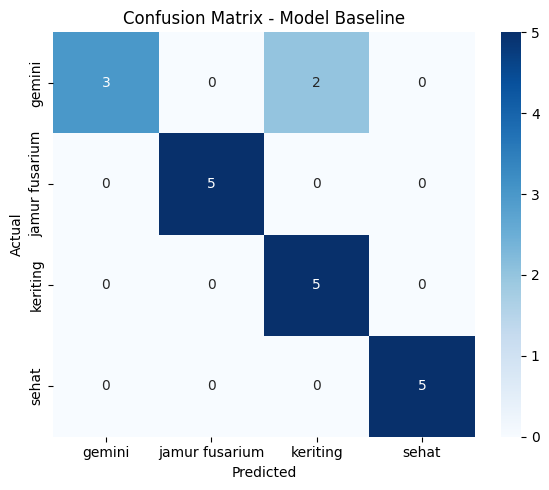

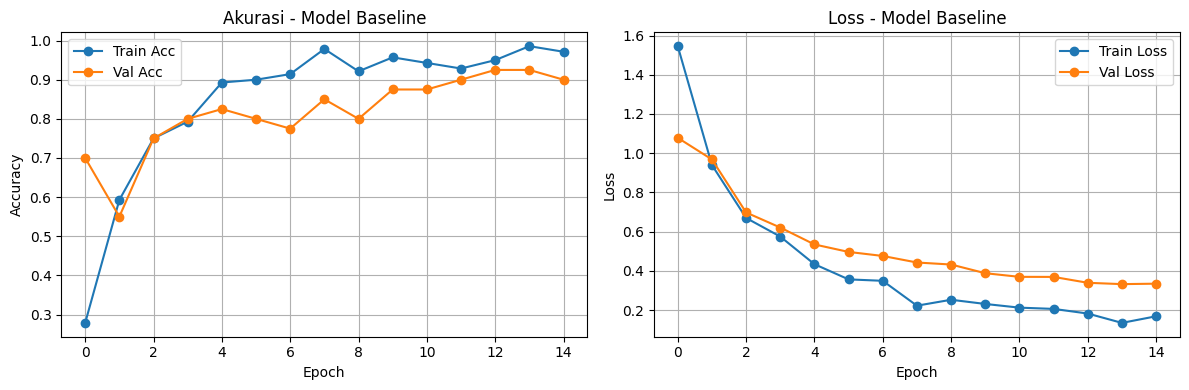

In [3]:
train_dir = '/content/Dataset/train'
val_dir   = '/content/Dataset/val'
test_dir  = '/content/Dataset/test'

# Validation & Test Generator
val_datagen  = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

val_gen  = val_datagen.flow_from_directory(val_dir, target_size=(224, 224), batch_size=8, class_mode='categorical')
test_gen = test_datagen.flow_from_directory(test_dir, target_size=(224, 224), batch_size=8, class_mode='categorical', shuffle=False)

# Training Generator Baseline
train_datagen_base = ImageDataGenerator(
    rescale=1./255, rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, fill_mode='nearest'
)
train_gen_base = train_datagen_base.flow_from_directory(train_dir, target_size=(224, 224), batch_size=8, class_mode='categorical')

# ==================== TRAINING / LOAD BASELINE ====================
model_path = os.path.join(SAVE_DIR, 'model_baseline.keras')
history_base = None
train_time_base = 0.0

if os.path.exists(model_path):
    print(" Model Baseline ditemukan di Google Drive! Memuat model langsung...")
    model_baseline = tf.keras.models.load_model(model_path)
else:
    print(" Model belum ada. Memulai training Baseline (15 Epoch)...")
    model_baseline = create_model(dropout_rate=0.2)
    model_baseline.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    start_t = time.perf_counter()
    history_base = model_baseline.fit(train_gen_base, epochs=15, validation_data=val_gen)
    train_time_base = time.perf_counter() - start_t

    model_baseline.save(model_path)
    print("✓ Model Baseline berhasil disimpan ke Drive!")

hasil_base = evaluate_and_plot(model_baseline, history_base, test_gen, "Model Baseline", train_time_base)


--- SKENARIO 1: SPLIT DATA 80:20 ---
Found 112 images belonging to 4 classes.
Found 28 images belonging to 4 classes.
Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2768 - loss: 1.5729 - val_accuracy: 0.5000 - val_loss: 1.0258
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6696 - loss: 0.9657 - val_accuracy: 0.7857 - val_loss: 0.7204
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8125 - loss: 0.6384 - val_accuracy: 0.9643 - val_loss: 0.5414
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8304 - loss: 0.4824 - val_accuracy: 0.9286 - val_loss: 0.4720
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9196 - loss: 0.3584 - val_accuracy: 0.9286 - val_loss: 0.4504
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9464 - loss: 0.3197 - val_accuracy: 0.9643 - val_loss: 0.4167
Epoch 7/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9375 - loss: 0.2663 - val_accuracy: 0.9286 - val_loss: 0.4377

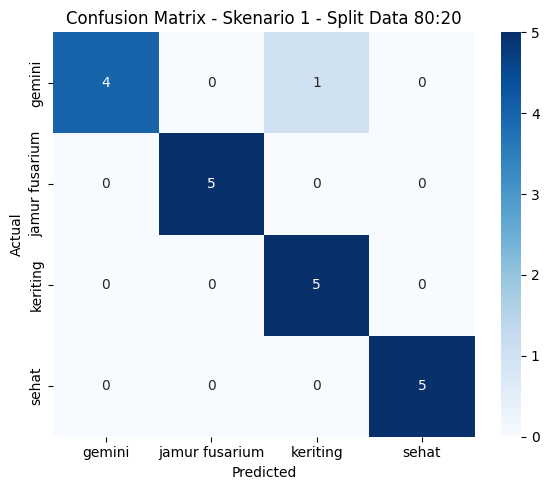

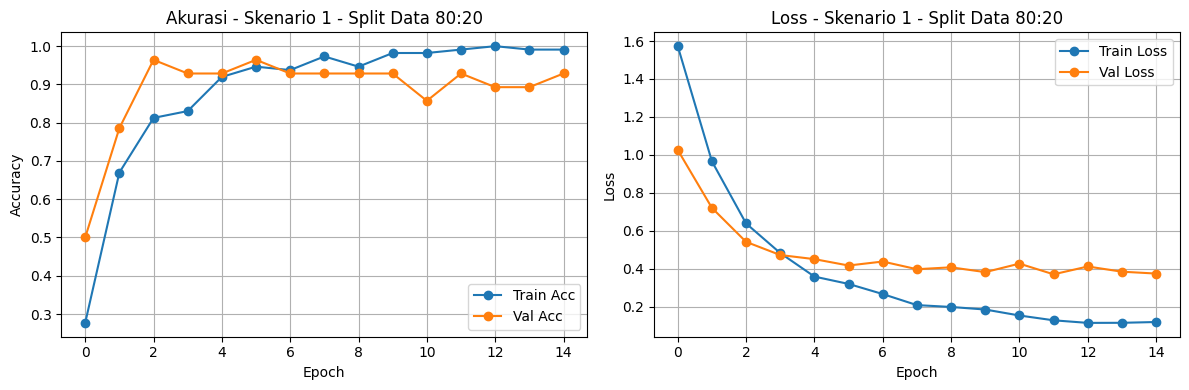

In [4]:
print("\n--- SKENARIO 1: SPLIT DATA 80:20 ---")
model_path = os.path.join(SAVE_DIR, 'model_skenario_1.keras')
history_s1 = None
train_time_s1 = 0.0

if os.path.exists(model_path):
    print("✓ Model Skenario 1 ditemukan di Drive! Memuat model...")
    model_s1 = tf.keras.models.load_model(model_path)
else:
    split_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
    train_gen_s1 = split_datagen.flow_from_directory(train_dir, target_size=(224, 224), batch_size=8, class_mode='categorical', subset='training')
    val_gen_s1   = split_datagen.flow_from_directory(train_dir, target_size=(224, 224), batch_size=8, class_mode='categorical', subset='validation')

    model_s1 = create_model(dropout_rate=0.2)
    model_s1.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])

    start_t = time.perf_counter()
    history_s1 = model_s1.fit(train_gen_s1, epochs=15, validation_data=val_gen_s1)
    train_time_s1 = time.perf_counter() - start_t

    model_s1.save(model_path)
    print("✓ Model Skenario 1 berhasil disimpan ke Drive!")

hasil_s1 = evaluate_and_plot(model_s1, history_s1, test_gen, "Skenario 1 - Split Data 80:20", train_time_s1)


--- SKENARIO 2A: TANPA DATA AUGMENTASI ---
Found 140 images belonging to 4 classes.
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.3071 - loss: 1.4694 - val_accuracy: 0.7000 - val_loss: 0.9260
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.6714 - loss: 0.8950 - val_accuracy: 0.8250 - val_loss: 0.6658
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8500 - loss: 0.5489 - val_accuracy: 0.8500 - val_loss: 0.5524
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8571 - loss: 0.4450 - val_accuracy: 0.8750 - val_loss: 0.4692
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9143 - loss: 0.3607 - val_accuracy: 0.8750 - val_loss: 0.4171
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9429 - loss: 0.2775 - val_accuracy: 0.9000 - val_loss: 0.3782
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.9429 - loss: 0.2487 - val_accuracy: 0.9250 - val_loss: 0.3493
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━


 METRIK EVALUASI:
   • Akurasi         : 90.00%
   • F1-Score        : 0.8958
   • ROC-AUC         : 1.0000
    Waktu Training  : 351.46 detik
    Waktu Prediksi  : 5.40 detik (20 sampel)

 CLASSIFICATION REPORT:
                precision    recall  f1-score   support

        gemini     1.0000    0.6000    0.7500         5
jamur fusarium     1.0000    1.0000    1.0000         5
      keriting     0.7143    1.0000    0.8333         5
         sehat     1.0000    1.0000    1.0000         5

      accuracy                         0.9000        20
     macro avg     0.9286    0.9000    0.8958        20
  weighted avg     0.9286    0.9000    0.8958        20



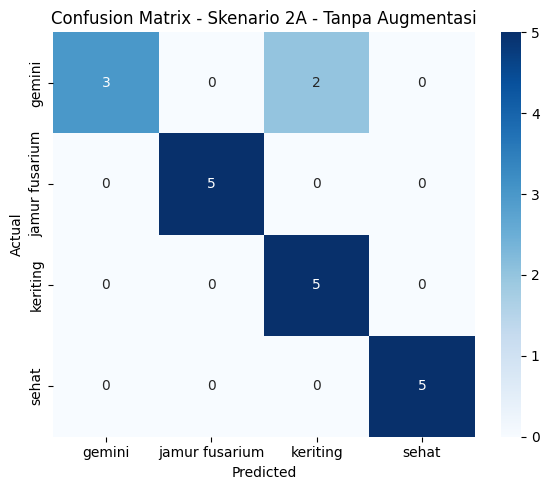

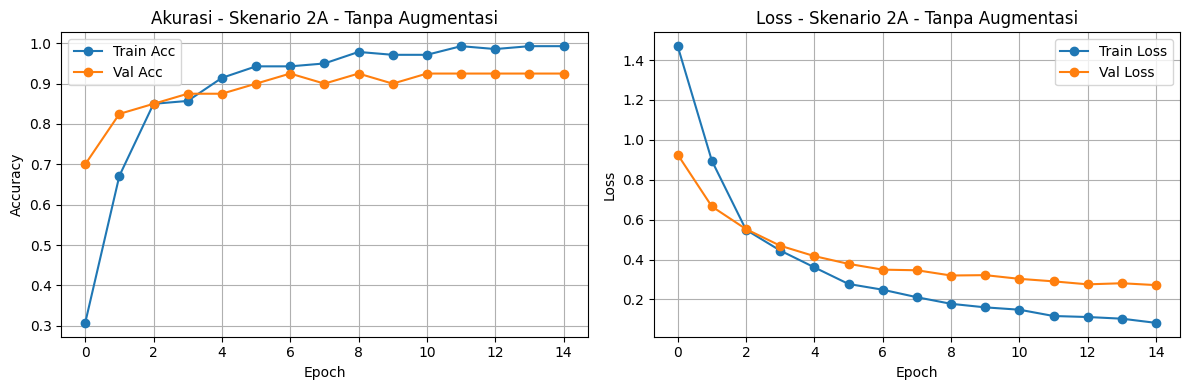


--- SKENARIO 2B: DENGAN DATA AUGMENTASI ---
Found 140 images belonging to 4 classes.
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.2786 - loss: 1.5220 - val_accuracy: 0.5000 - val_loss: 1.1187
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.5857 - loss: 0.9451 - val_accuracy: 0.5250 - val_loss: 0.9518
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.7714 - loss: 0.6707 - val_accuracy: 0.7000 - val_loss: 0.7701
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.8214 - loss: 0.5520 - val_accuracy: 0.8000 - val_loss: 0.6589
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.8643 - loss: 0.4390 - val_accuracy: 0.8250 - val_loss: 0.5823
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8786 - loss: 0.4241 - val_accuracy: 0.8250 - val_loss: 0.5410
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8500 - loss: 0.4171 - val_accuracy: 0.8750 - val_loss: 0.4788
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━

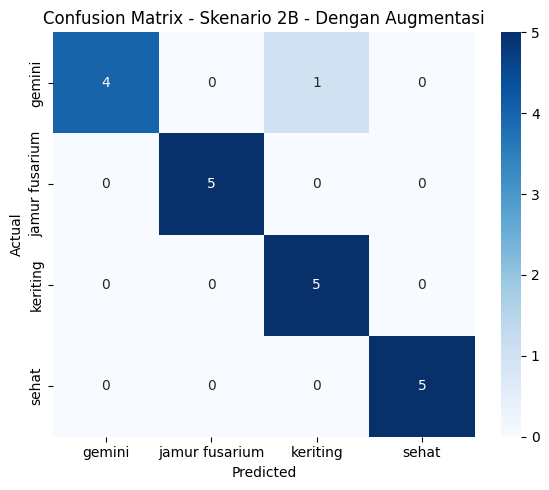

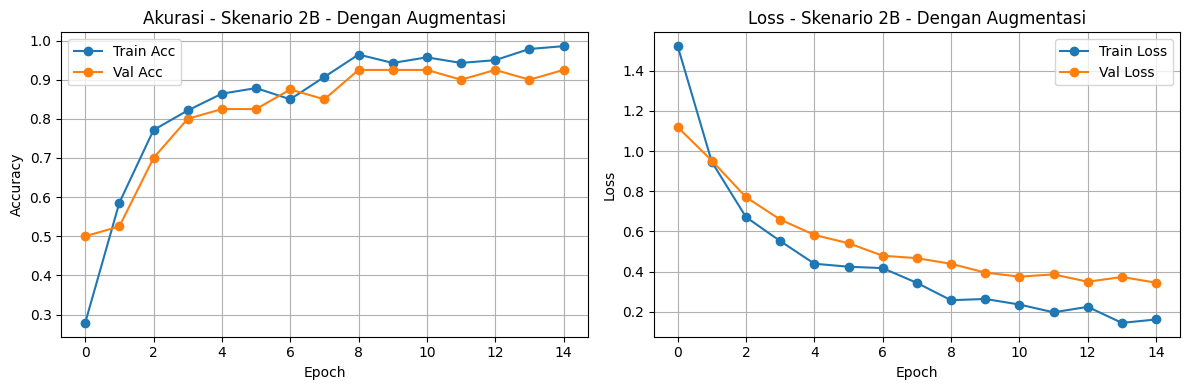

In [5]:
# ==================== SKENARIO 2A: TANPA AUGMENTASI ====================
print("\n--- SKENARIO 2A: TANPA DATA AUGMENTASI ---")
model_path_s2a = os.path.join(SAVE_DIR, 'model_skenario_2a_no_aug.keras')
history_s2a = None
train_time_s2a = 0.0

if os.path.exists(model_path_s2a):
    print("✓ Model Skenario 2A ditemukan di Drive! Memuat model...")
    model_s2a = tf.keras.models.load_model(model_path_s2a)
else:
    train_gen_no_aug = ImageDataGenerator(rescale=1./255).flow_from_directory(
        train_dir, target_size=(224, 224), batch_size=8, class_mode='categorical'
    )
    model_s2a = create_model(dropout_rate=0.2)
    model_s2a.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])

    start_t = time.perf_counter()
    history_s2a = model_s2a.fit(train_gen_no_aug, epochs=15, validation_data=val_gen)
    train_time_s2a = time.perf_counter() - start_t

    model_s2a.save(model_path_s2a)
    print("✓ Model Skenario 2A berhasil disimpan ke Drive!")

hasil_s2a = evaluate_and_plot(model_s2a, history_s2a, test_gen, "Skenario 2A - Tanpa Augmentasi", train_time_s2a)


# ==================== SKENARIO 2B: DENGAN AUGMENTASI ====================
print("\n--- SKENARIO 2B: DENGAN DATA AUGMENTASI ---")
model_path_s2b = os.path.join(SAVE_DIR, 'model_skenario_2b_with_aug.keras')
history_s2b = None
train_time_s2b = 0.0

if os.path.exists(model_path_s2b):
    print("✓ Model Skenario 2B ditemukan di Drive! Memuat model...")
    model_s2b = tf.keras.models.load_model(model_path_s2b)
else:
    train_gen_with_aug = ImageDataGenerator(
        rescale=1./255, rotation_range=25, horizontal_flip=True, zoom_range=0.2
    ).flow_from_directory(train_dir, target_size=(224, 224), batch_size=8, class_mode='categorical')

    model_s2b = create_model(dropout_rate=0.2)
    model_s2b.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])

    start_t = time.perf_counter()
    history_s2b = model_s2b.fit(train_gen_with_aug, epochs=15, validation_data=val_gen)
    train_time_s2b = time.perf_counter() - start_t

    model_s2b.save(model_path_s2b)
    print("✓ Model Skenario 2B berhasil disimpan ke Drive!")

hasil_s2b = evaluate_and_plot(model_s2b, history_s2b, test_gen, "Skenario 2B - Dengan Augmentasi", train_time_s2b)

Found 140 images belonging to 4 classes.

--- SKENARIO 3: OPTIMIZER Adam ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.3429 - loss: 1.5470 - val_accuracy: 0.4750 - val_loss: 1.1295
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.6000 - loss: 0.9491 - val_accuracy: 0.5750 - val_loss: 0.8817
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8143 - loss: 0.6523 - val_accuracy: 0.7750 - val_loss: 0.7052
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8643 - loss: 0.5055 - val_accuracy: 0.8000 - val_loss: 0.6151
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8786 - loss: 0.3910 - val_accuracy: 0.8500 - val_loss: 0.5462
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.8786 - loss: 0.3385 - val_accuracy: 0.8250 - val_loss: 0.5128
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.8929 - loss: 0.3235 - val_accuracy: 0.8750 - val_loss: 0.4709
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s

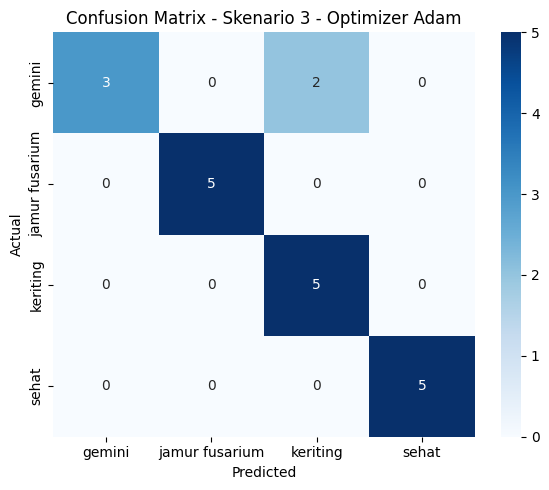

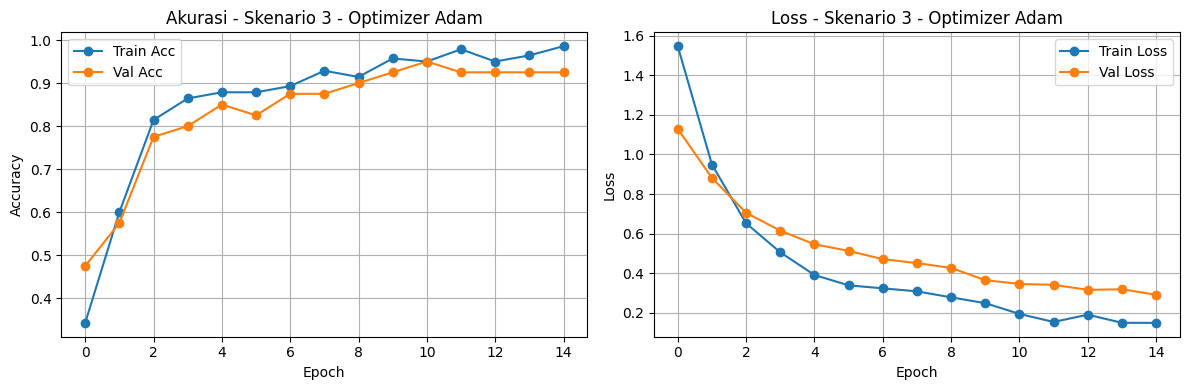


--- SKENARIO 3: OPTIMIZER SGD ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.2929 - loss: 1.7439 - val_accuracy: 0.5750 - val_loss: 1.1414
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.6214 - loss: 0.9713 - val_accuracy: 0.7250 - val_loss: 0.7528
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.7643 - loss: 0.6058 - val_accuracy: 0.6750 - val_loss: 0.8279
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8000 - loss: 0.5332 - val_accuracy: 0.7250 - val_loss: 0.6120
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8429 - loss: 0.4196 - val_accuracy: 0.7750 - val_loss: 0.6485
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8857 - loss: 0.3832 - val_accuracy: 0.8500 - val_loss: 0.4946
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.9286 - loss: 0.2905 - val_accuracy: 0.8500 - val_loss: 0.4549
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9143 - loss: 0.2538

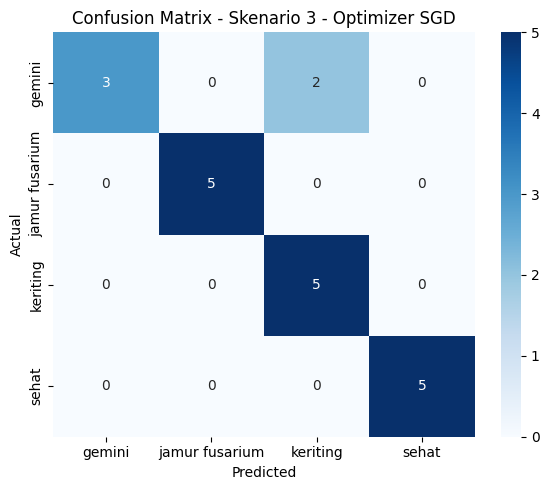

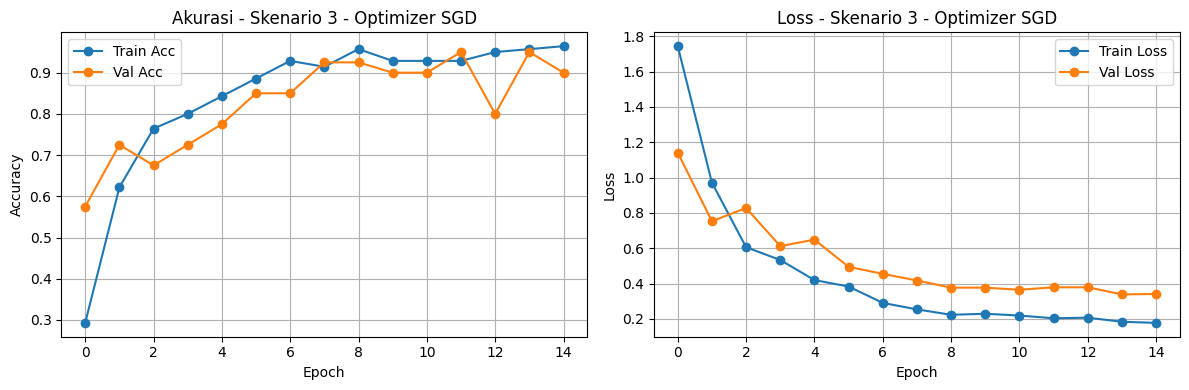


--- SKENARIO 3: OPTIMIZER RMSprop ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.4929 - loss: 1.2604 - val_accuracy: 0.5250 - val_loss: 1.0718
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7071 - loss: 0.7387 - val_accuracy: 0.7500 - val_loss: 0.7876
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7714 - loss: 0.5967 - val_accuracy: 0.7250 - val_loss: 0.6788
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.9000 - loss: 0.4211 - val_accuracy: 0.7750 - val_loss: 0.6564
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8643 - loss: 0.4240 - val_accuracy: 0.6250 - val_loss: 0.7432
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8929 - loss: 0.3404 - val_accuracy: 0.8000 - val_loss: 0.4885
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8929 - loss: 0.3126 - val_accuracy: 0.8750 - val_loss: 0.4383
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.9286 - loss: 0.

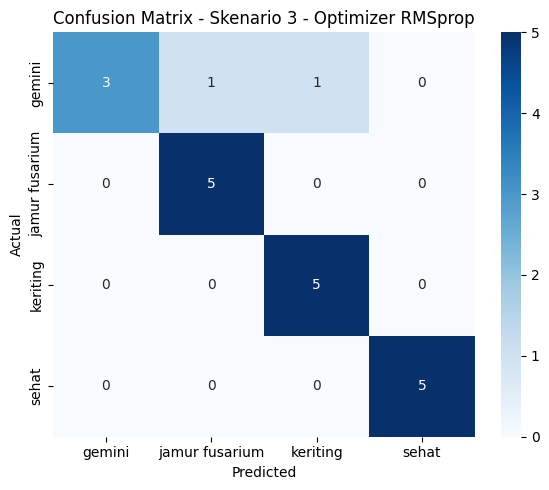

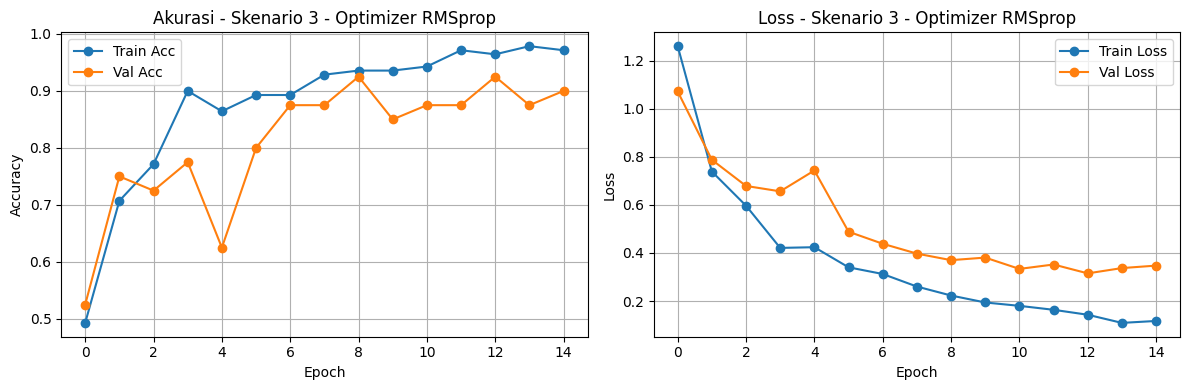

In [6]:
train_gen_std = ImageDataGenerator(
    rescale=1./255, rotation_range=20, horizontal_flip=True
).flow_from_directory(train_dir, target_size=(224, 224), batch_size=8, class_mode='categorical')

optimizers_dict = {
    "Adam": Adam(learning_rate=0.001),
    "SGD": SGD(learning_rate=0.001, momentum=0.9),
    "RMSprop": RMSprop(learning_rate=0.001)
}

hasil_s3 = {}

for name, opt in optimizers_dict.items():
    print(f"\n--- SKENARIO 3: OPTIMIZER {name} ---")
    model_path = os.path.join(SAVE_DIR, f'model_skenario_3_{name}.keras')
    history_s3 = None
    train_time_s3 = 0.0

    if os.path.exists(model_path):
        print(f"✓ Model Optimizer {name} ditemukan di Drive! Memuat model...")
        model_s3 = tf.keras.models.load_model(model_path)
    else:
        model_s3 = create_model(dropout_rate=0.2)
        model_s3.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

        start_t = time.perf_counter()
        history_s3 = model_s3.fit(train_gen_std, epochs=15, validation_data=val_gen)
        train_time_s3 = time.perf_counter() - start_t

        model_s3.save(model_path)
        print(f"✓ Model Skenario 3 ({name}) berhasil disimpan ke Drive!")

    hasil_s3[name] = evaluate_and_plot(model_s3, history_s3, test_gen, f"Skenario 3 - Optimizer {name}", train_time_s3)


--- SKENARIO 4: DROPOUT RATE = 0.0 ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.2286 - loss: 1.6850 - val_accuracy: 0.4250 - val_loss: 1.3892
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.6571 - loss: 0.9330 - val_accuracy: 0.6250 - val_loss: 0.9912
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.8143 - loss: 0.6424 - val_accuracy: 0.6750 - val_loss: 0.8242
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8571 - loss: 0.5028 - val_accuracy: 0.7250 - val_loss: 0.6599
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.9286 - loss: 0.3811 - val_accuracy: 0.8000 - val_loss: 0.5987
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.9429 - loss: 0.3348 - val_accuracy: 0.8750 - val_loss: 0.5099
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.9286 - loss: 0.2950 - val_accuracy: 0.9000 - val_loss: 0.4598
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9857 - loss: 0

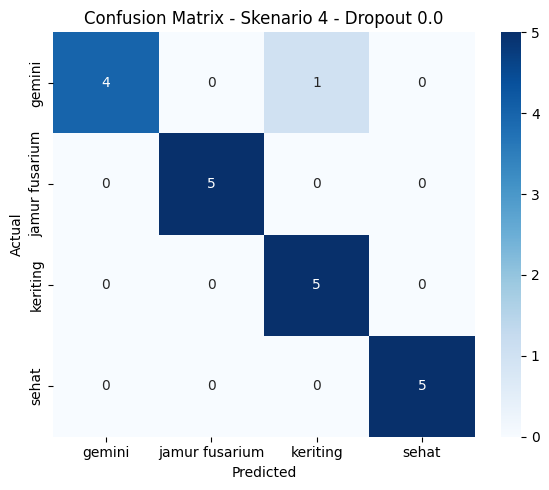

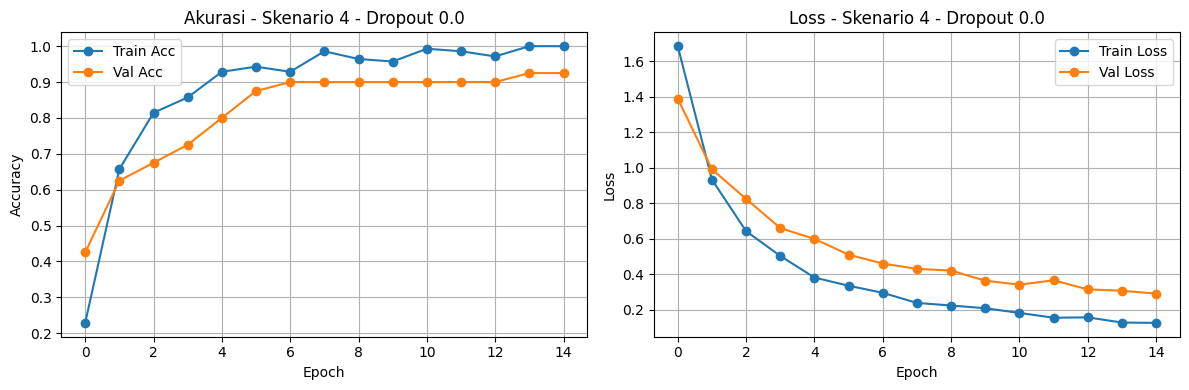


--- SKENARIO 4: DROPOUT RATE = 0.2 ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.3286 - loss: 1.5660 - val_accuracy: 0.5500 - val_loss: 1.1227
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.5786 - loss: 0.9725 - val_accuracy: 0.7000 - val_loss: 0.8294
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8143 - loss: 0.6098 - val_accuracy: 0.8250 - val_loss: 0.7193
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8071 - loss: 0.5595 - val_accuracy: 0.7750 - val_loss: 0.6012
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8857 - loss: 0.3964 - val_accuracy: 0.7500 - val_loss: 0.5397
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.9071 - loss: 0.3572 - val_accuracy: 0.8250 - val_loss: 0.5048
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8714 - loss: 0.3847 - val_accuracy: 0.8500 - val_loss: 0.4409
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.9500 - loss: 0

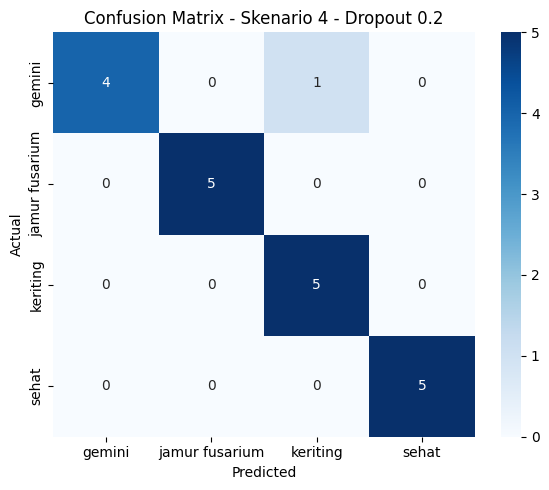

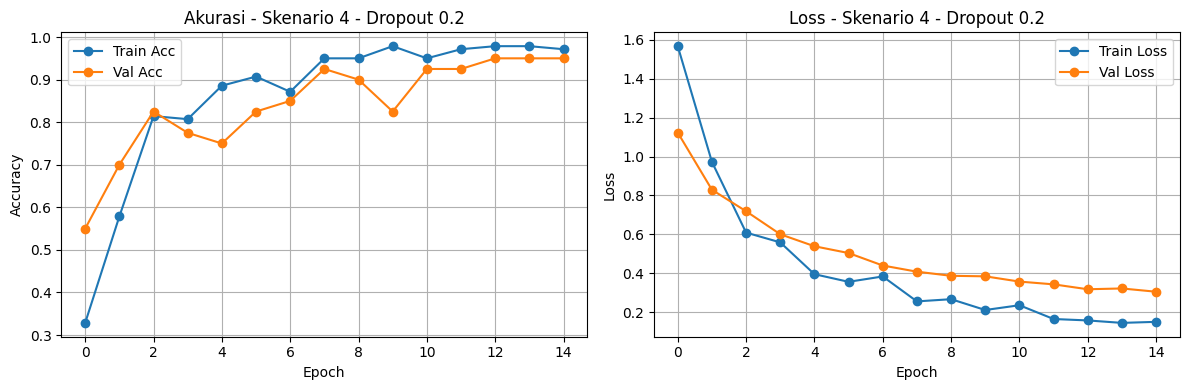


--- SKENARIO 4: DROPOUT RATE = 0.5 ---
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.2857 - loss: 1.7601 - val_accuracy: 0.4000 - val_loss: 1.2371
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.4929 - loss: 1.1934 - val_accuracy: 0.4500 - val_loss: 1.0543
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.5714 - loss: 0.9863 - val_accuracy: 0.7000 - val_loss: 0.8194
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.6357 - loss: 0.8390 - val_accuracy: 0.7500 - val_loss: 0.7496
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6429 - loss: 0.8102 - val_accuracy: 0.7250 - val_loss: 0.6594
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7714 - loss: 0.6042 - val_accuracy: 0.7750 - val_loss: 0.6076
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8500 - loss: 0.4963 - val_accuracy: 0.8250 - val_loss: 0.5395
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8714 - loss: 0

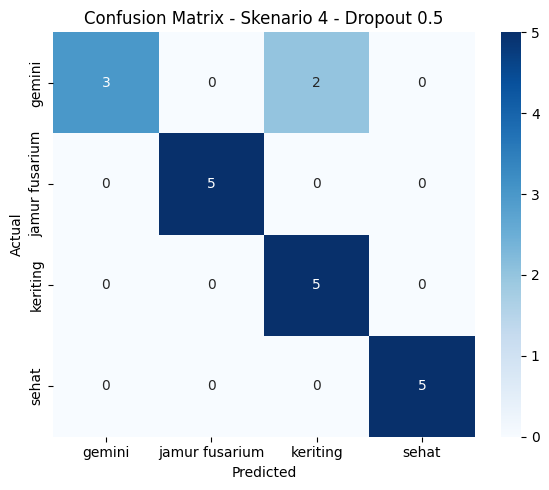

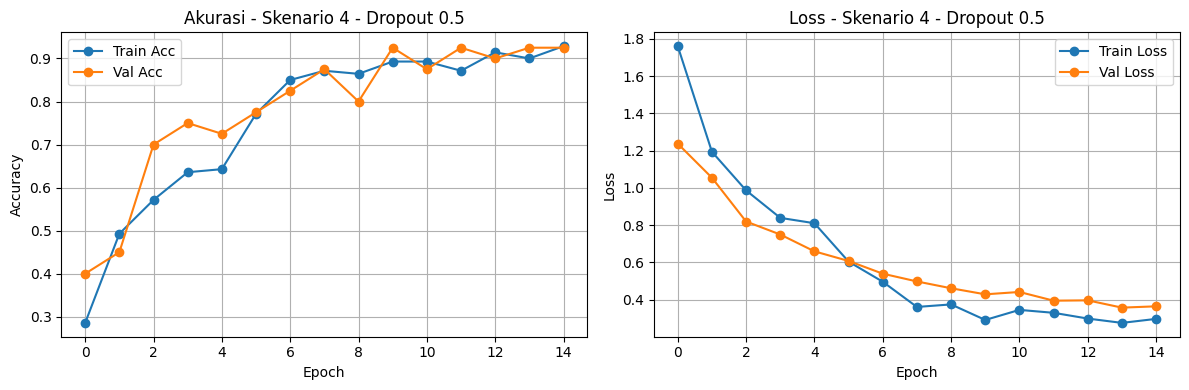

In [7]:
dropout_rates = [0.0, 0.2, 0.5]
hasil_s4 = {}

for rate in dropout_rates:
    rate_str = str(rate).replace('.', '_')
    print(f"\n--- SKENARIO 4: DROPOUT RATE = {rate} ---")
    model_path = os.path.join(SAVE_DIR, f'model_skenario_4_dropout_{rate_str}.keras')
    history_s4 = None
    train_time_s4 = 0.0

    if os.path.exists(model_path):
        print(f"✓ Model Dropout {rate} ditemukan di Drive! Memuat model...")
        model_s4 = tf.keras.models.load_model(model_path)
    else:
        model_s4 = create_model(dropout_rate=rate)
        model_s4.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])

        start_t = time.perf_counter()
        history_s4 = model_s4.fit(train_gen_std, epochs=15, validation_data=val_gen)
        train_time_s4 = time.perf_counter() - start_t

        model_s4.save(model_path)
        print(f"✓ Model Skenario 4 (Dropout {rate}) berhasil disimpan ke Drive!")

    hasil_s4[rate] = evaluate_and_plot(model_s4, history_s4, test_gen, f"Skenario 4 - Dropout {rate}", train_time_s4)